In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

In [3]:
df=pd.read_csv("weatherAUS.csv")

In [4]:
df=df.sort_values("Date")

**First Exploration**

In [5]:
print("Supervised Classification Problem")
print("Main objective: predict RainTomorrow")

Supervised Classification Problem
Main objective: predict RainTomorrow


In [6]:
print("Freely available Dataset on Kaggle.com")
print("Dataset of 23 columns vs 145460 lines")
print("contains weather variables over 10years at different locations in Austrialia")


Freely available Dataset on Kaggle.com
Dataset of 23 columns vs 145460 lines
contains weather variables over 10years at different locations in Austrialia


In [7]:
print("7 categorical columns")
print("Column	Categories, Date 	49, WindGustDir	16, WindDir9am	16, WindDir3pm	16")
print("\n")
print("16 numerical columns")
print("MinTemp and MaxTemp, Pressure9am and Pressure 3pm, Temp9am and Temp3pm, Sunshine and Evaporation")

7 categorical columns
Column	Categories, Date 	49, WindGustDir	16, WindDir9am	16, WindDir3pm	16


16 numerical columns
MinTemp and MaxTemp, Pressure9am and Pressure 3pm, Temp9am and Temp3pm, Sunshine and Evaporation


In [8]:
print("Different Distributions for each Variable")
print("MinTemp	Normal, MaxTemp	Normal,Rainfall	Right-skewed,Evaporation	Right-skewed,\
Sunshine	bimodial,WindGustSpeed	Right-skewed, WindSpeed9am	Right-skewed\
WindSpeed3pm	Right-skewed,Humidity9am	Left-skewed,Humidity3pm	Normal,Pressure9am	Normal,Pressure3pm	Normal\
Cloud9am	bimodial,Cloud3pm	bimodial,Temp9am	Normal,Temp3pm	Normal")



Different Distributions for each Variable
MinTemp	Normal, MaxTemp	Normal,Rainfall	Right-skewed,Evaporation	Right-skewed,Sunshine	bimodial,WindGustSpeed	Right-skewed, WindSpeed9am	Right-skewedWindSpeed3pm	Right-skewed,Humidity9am	Left-skewed,Humidity3pm	Normal,Pressure9am	Normal,Pressure3pm	NormalCloud9am	bimodial,Cloud3pm	bimodial,Temp9am	Normal,Temp3pm	Normal


Examples of Distributions:


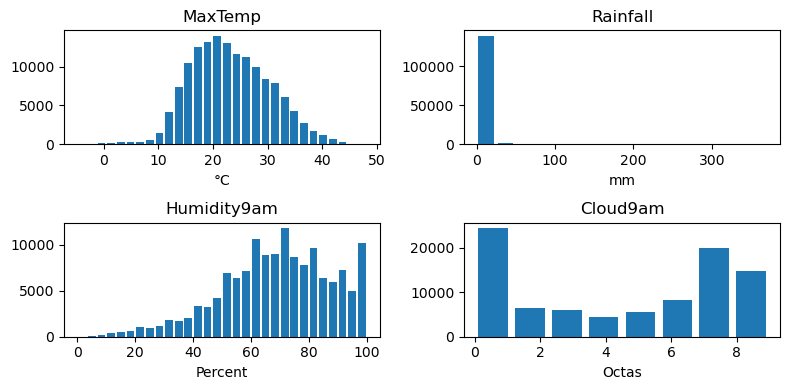

In [9]:
print("Examples of Distributions:")

plt.figure(figsize=(8,4))

plt.subplot(2,2,1)
plt.hist(df["MaxTemp"],bins=30, rwidth=0.8);
plt.xlabel("°C")
plt.title("MaxTemp")

plt.subplot(2,2,2)
plt.hist(df["Rainfall"],bins=15, rwidth=0.8);
plt.xlabel("mm")
plt.title("Rainfall")

plt.subplot(2,2,3)
plt.hist(df["Humidity9am"],bins=30, rwidth=0.8);
plt.xlabel("Percent")
plt.title("Humidity9am")

plt.subplot(2,2,4)
plt.hist(df["Cloud9am"],bins=8, rwidth=0.8);
plt.xlabel("Octas")
plt.title("Cloud9am");

plt.tight_layout();



In [10]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


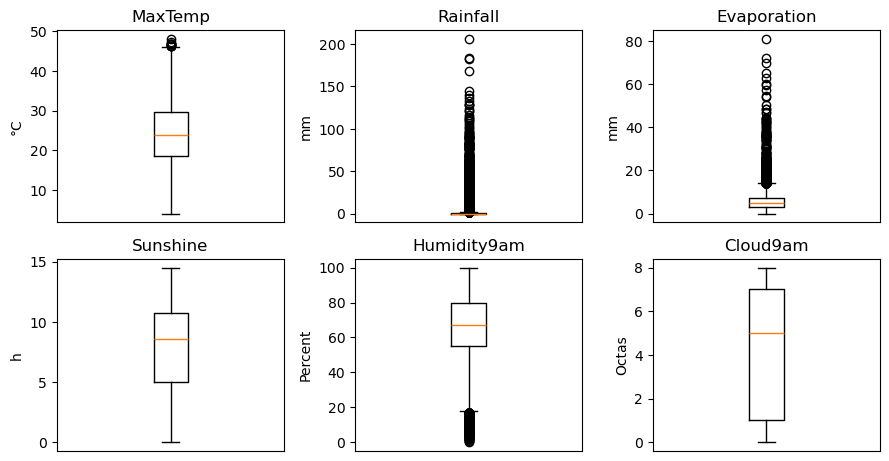

In [11]:
data_quant=df.select_dtypes(include=["float", "int"]).dropna()

plt.figure(figsize=(9,7))

plt.subplot(3,3,1)
plt.boxplot(data_quant.iloc[:,1]);
plt.ylabel("°C")
plt.title("MaxTemp")
plt.xticks([])

plt.subplot(3,3,2)
plt.boxplot(data_quant.iloc[:,2]);
plt.ylabel("mm")
plt.title("Rainfall")
plt.xticks([])

plt.subplot(3,3,3)
plt.boxplot(data_quant.iloc[:,3]);
plt.ylabel("mm")
plt.title("Evaporation")
plt.xticks([])

plt.subplot(3,3,4)
plt.boxplot(data_quant.iloc[:,4]);
plt.ylabel("h")
plt.title("Sunshine")
plt.xticks([])

plt.subplot(3,3,5)
plt.boxplot(data_quant.iloc[:,8]);
plt.ylabel("Percent")
plt.title("Humidity9am")
plt.xticks([])

plt.subplot(3,3,6)
plt.boxplot(data_quant.iloc[:,12]);
plt.ylabel("Octas")
plt.title("Cloud9am");
plt.xticks([])

plt.tight_layout();

**Checking for Duplicates**

In [12]:
df.duplicated().sum()

0

**Dropping NAs**

In [13]:
##df["Sunshine"].value_counts(dropna=False, normalize=True)
##df["Evaporation"].value_counts(dropna=False, normalize=True)
##df["Cloud3pm"].value_counts(dropna=False, normalize=True)

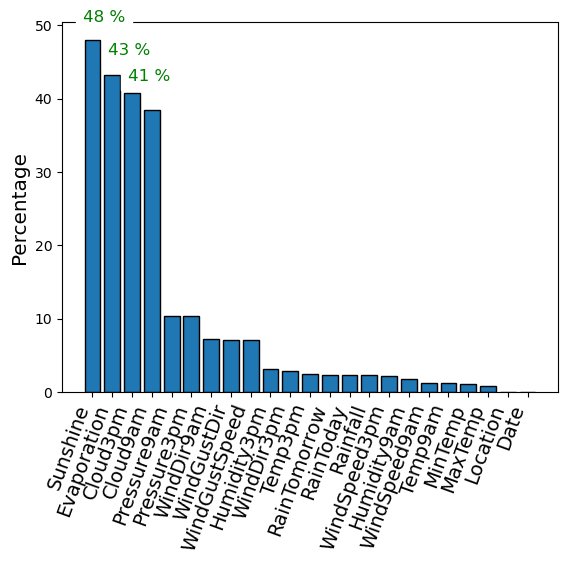

In [14]:
sorti=pd.DataFrame()

for i,n in enumerate(df.isna().sum()):
    sorti1=pd.DataFrame({df.columns[i]:[100*n/145460]})
    sorti=pd.concat([sorti1, sorti], axis=1)    
    
sorti2=sorti.transpose()
sorti3=sorti2.sort_values(by=[0], ascending=False)

plt.bar(sorti3.index, sorti3[0], edgecolor="black")
plt.xticks(rotation=70, ha="right", fontsize=14)
plt.ylabel("Percentage",size="x-large")
plt.text(-0.5,50.5,"48 %", color="green", backgroundcolor="w", fontsize="large");
plt.text(0.8,46,"43 %", color="green", backgroundcolor="w", fontsize="large");
plt.text(1.8,42.5,"41 %", color="green", backgroundcolor="w", fontsize="large");

#plt.suptitle("The Dataset contains plenty NA values");


In [15]:
df2=df.dropna(axis = 0, how = 'all', subset = ["RainTomorrow"])

df2=df2.drop(["Evaporation", "Sunshine", "Cloud3pm"], axis=1)



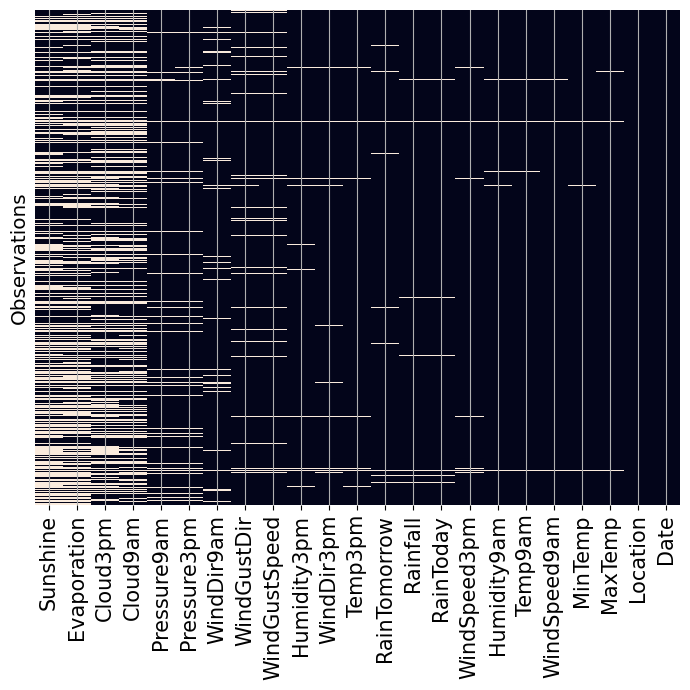

In [16]:
missing_values = df.isna().sum().sort_values(ascending=False)

plt.figure(figsize=(7, 7))
ax=sns.heatmap(df[missing_values.index].isna(), 
            cbar=False,
            yticklabels=False)
#plt.title("Map of Missing Values in the Dataset", fontsize=14)

plt.ylabel("Observations",size="x-large")
ax.tick_params(axis="x", labelsize=15)
plt.tight_layout()
plt.grid(True)
plt.show();


In [17]:
df2=df2[df.isna().sum(axis=1) < 11]

#I still accept 50%, I dont accept 55%
#5062 rows of 145460

C:\Users\Irmigeheuer\AppData\Local\Temp\ipykernel_24356\3407417776.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df2=df2[df.isna().sum(axis=1) < 11]


**Numeric Variables**

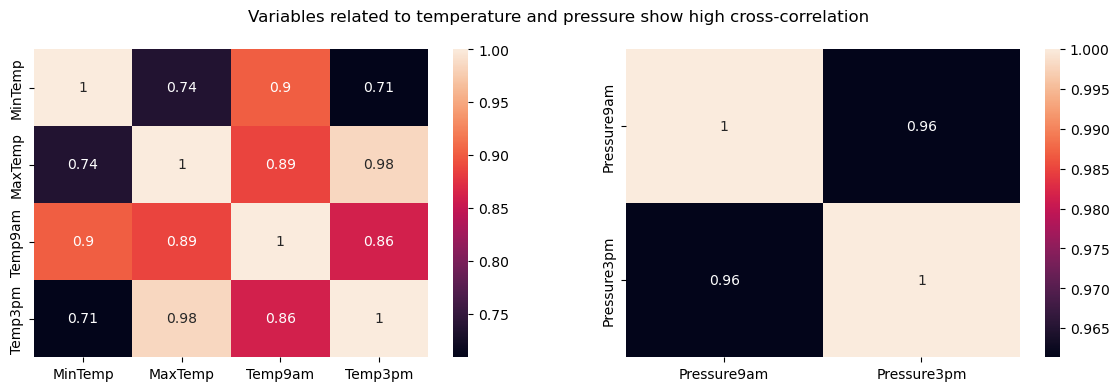

In [18]:
df_temp=df2[["MinTemp", "MaxTemp", "Temp9am", "Temp3pm"]]
df_press=df2[["Pressure9am", "Pressure3pm"]]

corr_temp=df_temp.corr()
corr_press=df_press.corr()

plt.figure(figsize=(14,4))
plt.suptitle("Variables related to temperature and pressure show high cross-correlation")
plt.subplot(1,2,1)
ax=sns.heatmap(corr_temp, annot= True)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10);

plt.subplot(1,2,2)
ax1=sns.heatmap(corr_press, annot= True)
ax1.tick_params(axis="both", labelsize=10);

In [19]:
df2=df2.dropna(axis = 0, how = 'all', subset = ["RainTomorrow"])

df2=df2.drop(["MinTemp", "Temp3pm", "Pressure9am"], axis=1)


In [20]:
data_num=df2.select_dtypes(include=["int", "float"]).dropna()


corr_num=data_num.corr()

corr_num

,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure3pm,Cloud9am,Temp9am
MaxTemp,1.000000,-0.053051,0.062923,0.007537,0.012078,-0.534620,-0.485579,-0.444612,-0.289721,0.897491
Rainfall,-0.053051,1.000000,0.121962,0.069432,0.056594,0.235330,0.261505,-0.139026,0.198539,0.027021
WindGustSpeed,0.062923,0.121962,1.000000,0.608922,0.689688,-0.193430,-0.034989,-0.397809,0.072411,0.119892
WindSpeed9am,0.007537,0.069432,0.608922,1.000000,0.508908,-0.236194,-0.041874,-0.168423,0.023381,0.083370
WindSpeed3pm,0.012078,0.056594,0.689688,0.508908,1.000000,-0.100955,0.029095,-0.255602,0.057724,0.110749
Humidity9am,-0.534620,0.235330,-0.193430,-0.236194,-0.100955,1.000000,0.696978,0.175418,0.459098,-0.470537
Humidity3pm,-0.485579,0.261505,-0.034989,-0.041874,0.029095,0.696978,1.000000,0.029711,0.523314,-0.202942
Pressure3pm,-0.444612,-0.139026,-0.397809,-0.168423,-0.255602,0.175418,0.029711,1.000000,-0.069556,-0.492510
Cloud9am,-0.289721,0.198539,0.072411,0.023381,0.057724,0.459098,0.523314,-0.069556,1.000000,-0.142685
Temp9am,0.897491,0.027021,0.119892,0.083370,0.110749,-0.470537,-0.202942,-0.492510,-0.142685,1.000000


**converting Date**

In [21]:
df2["Date"]=pd.to_datetime(df2["Date"], format="%Y-%m-%d")


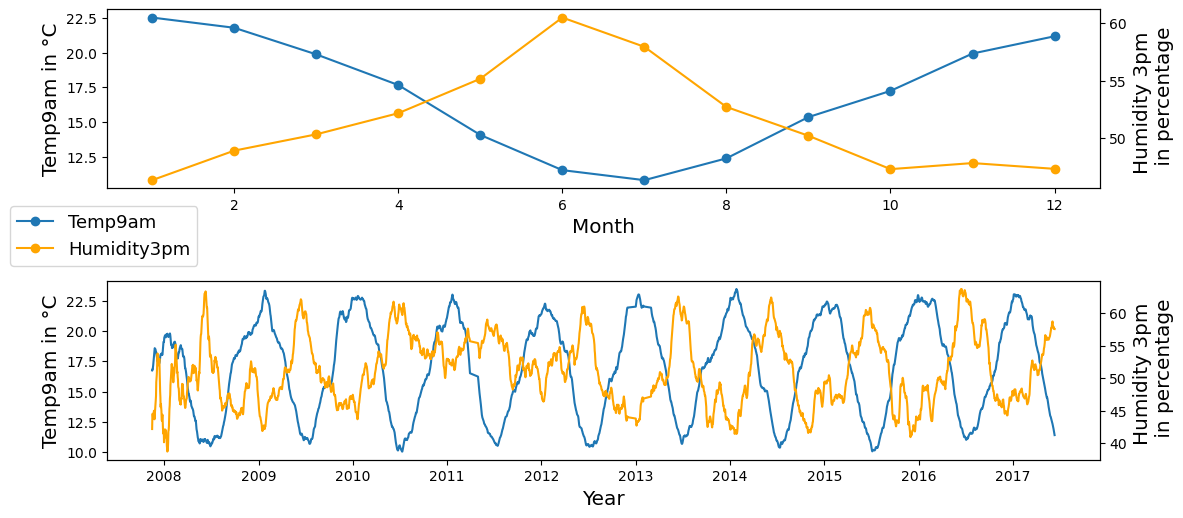

In [22]:

###################### month ##############################

monthly_temp = df2.groupby(df2["Date"].dt.month)["Temp9am"].mean()
monthly_hum = df2.groupby(df2["Date"].dt.month)["Humidity3pm"].mean()

fig = plt.figure(figsize=(12, 8))
ax1 = fig.add_subplot(312)
ax1.plot(monthly_temp, marker="o", label="Temp9am")
ax1.set_ylabel('Temp9am in °C', size="x-large")
ax1.set_xlabel("Month", size="x-large")

ax2 = ax1.twinx()   
ax2.plot(monthly_hum, "orange", marker="o", label="Humidity3pm")
ax2.set_ylabel('Humidity 3pm \n in percentage', size="x-large");

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=[0.1,-0.05], fontsize=13)


###################### year ##############################

daily_temp = df2.groupby("Date")["Temp9am"].mean().rolling(30, center=True).mean()
daily_hum = df2.groupby("Date")["Humidity3pm"].mean().rolling(30, center=True).mean()


ax3 = fig.add_subplot(313)
ax3.plot(daily_temp)
ax3.set_ylabel('Temp9am in °C', size="x-large")
ax3.set_xlabel("Year", size="x-large")

ax4 = ax3.twinx()   
ax4.plot(daily_hum, "orange")
ax4.set_ylabel('Humidity 3pm \n in percentage', size="x-large")

plt.tight_layout();






**Categorical Variables**


In [23]:
Windcorr=pd.DataFrame(columns=["RainTomorrow - p-Value","RainTomorrow - Cramer's V"])

data_qual=df.select_dtypes(include=["object"]).dropna().drop("RainTomorrow", axis=1).drop("Date",axis=1)

from scipy.stats import chi2_contingency

for n in data_qual.columns:
    ct=pd.crosstab(data_qual[n],df2["RainTomorrow"])

    stat, p = chi2_contingency(ct)[:2]

    V_Cramer = np.sqrt(stat/ct.values.sum())
    if ((p < 0.05) & (V_Cramer > 0.1)):
#        print(n, "chi2 value is: ",chi2_contingency(ct)[0])
        print("For Column: ",n)
        print("p value is: ",chi2_contingency(ct)[1])
        print("V Cramer is: ",round(V_Cramer,3))
        print("\n")

    temporaldf = pd.DataFrame({"RainTomorrow - p-Value": [round(p,3)],"RainTomorrow - Cramer's V": [round(V_Cramer, 3)]},index=[n])
    Windcorr = pd.concat([Windcorr, temporaldf])

Windcorr

For Column:  Location
p value is:  0.0
V Cramer is:  0.165


For Column:  WindGustDir
p value is:  0.0
V Cramer is:  0.112


For Column:  WindDir9am
p value is:  0.0
V Cramer is:  0.132


For Column:  WindDir3pm
p value is:  1.902558880797873e-266
V Cramer is:  0.102


For Column:  RainToday
p value is:  0.0
V Cramer is:  0.316




,RainTomorrow - p-Value,RainTomorrow - Cramer's V
Location,0.0,0.165
WindGustDir,0.0,0.112
WindDir9am,0.0,0.132
WindDir3pm,0.0,0.102
RainToday,0.0,0.316


**Wind Columns**

In [24]:
windcols=["WindGustDir", "WindDir9am", "WindDir3pm"]

ct=pd.crosstab(df2["WindDir9am"],df2["WindDir3pm"])

stat, p = chi2_contingency(ct)[:2]

n = ct.values.sum()
k = min(ct.shape) - 1
V_Cramer = np.sqrt(stat / (n * k))

print("Relationship WindDir9am and WindDir3pm: ")
print("\n")
print("p value is: ", p)
print("V Cramer is: ", round(V_Cramer, 3))

Relationship WindDir9am and WindDir3pm: 


p value is:  0.0
V Cramer is:  0.202


In [25]:
windcols=["WindGustDir", "WindDir9am", "WindDir3pm"]

ct = pd.crosstab(df2["WindGustDir"], df2["WindDir3pm"])

stat, p = chi2_contingency(ct)[:2]

n = ct.values.sum()
k = min(ct.shape) - 1
V_Cramer = np.sqrt(stat / (n * k))

print("Relationship WindGustDir and WindDir3pm: ")
print("\n")
print("p value is: ", p)
print("V Cramer is: ", round(V_Cramer, 3))

Relationship WindGustDir and WindDir3pm: 


p value is:  0.0
V Cramer is:  0.347


In [26]:
dirs = ["N","NNE","NE","ENE","E","ESE","SE","SSE","S","SSW","SW","WSW","W","WNW","NW","NNW"]
angle = {d: i * 2 * np.pi / 16 for i, d in enumerate(dirs)}

df2["WindDir3pm_sin"] = df2["WindDir3pm"].map(angle).apply(np.sin)
df2["WindDir3pm_cos"] = df2["WindDir3pm"].map(angle).apply(np.cos)



In [27]:
df2=df2.drop(["WindDir9am", "WindGustDir", "WindDir3pm"], axis=1)

**Grouping Locations**

In [28]:
ct=pd.crosstab(df2["Location"],df2["RainTomorrow"])

stat, p = chi2_contingency(ct)[:2]

n = ct.values.sum()
k = min(ct.shape) - 1
V_Cramer = np.sqrt(stat / (n * k))

print("Correlation Locations to RainTomorrow: ")
print("\n")
print("p value is: ",chi2_contingency(ct)[1])
print("V Cramer is: ",round(V_Cramer,3))



Correlation Locations to RainTomorrow: 


p value is:  0.0
V Cramer is:  0.159


In [29]:
data = df2[["Location", "RainTomorrow"]].dropna().copy()

results = []

# filter for unique locations
for location in data["Location"].unique():

    # group locations
    data["Group"] = (
        data["Location"] == location
    ).map({True: "Selected", False: "Others"})

    # crosstab
    table = pd.crosstab(
        data["Group"],
        data["RainTomorrow"]
    ).reindex(
        index=["Selected", "Others"],
        columns=["Yes", "No"],
        fill_value=0
    )

    # Chi-Square Test
    chi2, p_value, dof, expected = chi2_contingency(table)

    # Rain Rate
    selected = data[data["Location"] == location]
    others = data[data["Location"] != location]

    rain_rate_location = (
        selected["RainTomorrow"].eq("Yes").mean()
    )
    rain_rate_others = (
        others["RainTomorrow"].eq("Yes").mean()
    )

    results.append({
        "Location": location,
#        "N": len(selected),
#        "RainRate": rain_rate_location,
#        "RainRate_Others": rain_rate_others,
#        "Difference_pp": 100 * (
#            rain_rate_location - rain_rate_others
#        ),
        "p_value": p_value
    })

# convert to DataFrame
results = pd.DataFrame(results)

# Holm-Correction
results["p_adjusted by Holm"] = multipletests(
    results["p_value"],
    method="holm"
)[1]

# Significance
results["Significant (p<0.05)"] = results["p_adjusted by Holm"] < 0.05

# sort results
results = results.sort_values("p_adjusted by Holm")

print(results.round(4).to_string(index=False))

        Location  p_value  p_adjusted by Holm  Significant (p<0.05)
         Woomera   0.0000              0.0000                  True
    AliceSprings   0.0000              0.0000                  True
        Portland   0.0000              0.0000                  True
         Mildura   0.0000              0.0000                  True
         Walpole   0.0000              0.0000                  True
           Uluru   0.0000              0.0000                  True
           Cobar   0.0000              0.0000                  True
          Cairns   0.0000              0.0000                  True
        Dartmoor   0.0000              0.0000                  True
   NorfolkIsland   0.0000              0.0000                  True
           Moree   0.0000              0.0000                  True
    MountGambier   0.0000              0.0000                  True
          Albany   0.0000              0.0000                  True
     Witchcliffe   0.0000              0.0000   

In [30]:
locs=["Albury","Wollongong","Hobart", "Sale","Launceston","Brisbane","MelbourneAirport","Adelaide"]

locs_ind=df2.query("Location in @locs").index
#24470 rows of 142193 rows, 17.2%
df2=df2.drop(locs_ind)

In [31]:
df2_before_grouping = df2.copy()
df2_before_grouping["RainTomorrow"] = (df2_before_grouping["RainTomorrow"] == "Yes").astype(int)

In [32]:
loc_groups = {
    # Sydney Region
    "Sydney": "Sydney Region",
    "SydneyAirport": "Sydney Region",
    "BadgerysCreek": "Sydney Region",
    "Penrith": "Sydney Region",
    "Richmond": "Sydney Region",
    "NorahHead": "Sydney Region",
    "Wollongong": "Sydney Region",
    # NSW North Coast
    "Newcastle": "NSW North Coast",
    "Williamtown": "NSW North Coast",
    "CoffsHarbour": "NSW North Coast",
    # NSW Inland
    "Cobar": "NSW Inland",
    "Moree": "NSW Inland",
    "WaggaWagga": "NSW Inland",
    "Albury": "NSW Inland",
    # Canberra Region
    "Canberra": "Canberra Region",
    "Tuggeranong": "Canberra Region",
    "MountGinini": "Canberra Region",
    # Melbourne Region
    "Melbourne": "Melbourne Region",
    "MelbourneAirport": "Melbourne Region",
    "Watsonia": "Melbourne Region",
    # Victoria Inland East
    "Ballarat": "Victoria Inland East",
    "Bendigo": "Victoria Inland East",
    "Sale": "Victoria Inland East",
    # Southwest Victoria / Southeast SA
    "Portland": "Southwest Victoria",
    "Dartmoor": "Southwest Victoria",
    "MountGambier": "Southwest Victoria",
    # Murray / Northwest Victoria
    "Mildura": "Northwest Victoria",
    "Nhil": "Northwest Victoria",
    # Tasmania
    "Hobart": "Tasmania",
    "Launceston": "Tasmania",
    # South Australia
    "Adelaide": "South Australia",
    "Nuriootpa": "South Australia",
    "Woomera": "South Australia",
    # Southeast Queensland
    "Brisbane": "Southeast Queensland",
    "GoldCoast": "Southeast Queensland",
    # North Queensland
    "Cairns": "North Queensland",
    "Townsville": "North Queensland",
    # Top End (Northern Territory)
    "Darwin": "Top End NT",
    "Katherine": "Top End NT",
    # Central Australia
    "AliceSprings": "Central Australia",
    "Uluru": "Central Australia",
    # Perth Region
    "Perth": "Perth Region",
    "PerthAirport": "Perth Region",
    "PearceRAAF": "Perth Region",
    # Southwest Western Australia
    "Albany": "Southwest Western Australia",
    "Walpole": "Southwest Western Australia",
    "Witchcliffe": "Southwest Western Australia",
    "SalmonGums": "Southwest Western Australia",
    # Norfolk Island
    "NorfolkIsland": "Norfolk Island",
}

df2["Location"]=df2["Location"].replace(loc_groups)

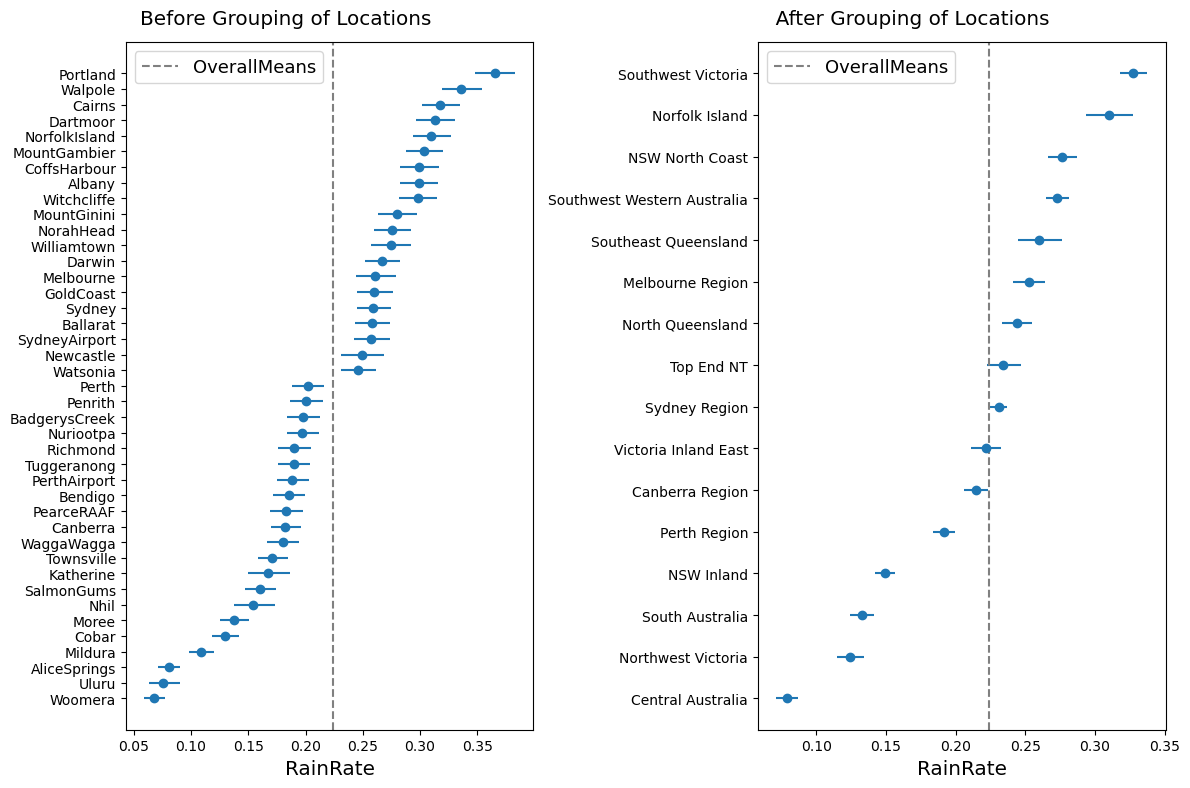

In [33]:
df2_after_grouping = df2.copy()
df2_after_grouping["RainTomorrow"] = (df2_after_grouping["RainTomorrow"] == "Yes").astype(int)

######################################################################################################
plt.figure(figsize=(12,8))

plt.subplot(1,2,1)

g = df2_before_grouping.groupby("Location")["RainTomorrow"].agg(k="sum", n="count")
g["rate"] = g["k"] / g["n"]
g["lo"], g["hi"] = proportion_confint(g["k"], g["n"], method="wilson")
g = g.sort_values("rate")


plt.errorbar(g["rate"], range(len(g)),
             xerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="o")
plt.yticks(range(len(g)), g.index)
plt.axvline(df2_before_grouping["RainTomorrow"].mean(), color="gray", ls="--", label="OverallMeans")
plt.xlabel("RainRate", size="x-large")
plt.legend(loc='upper left', fontsize=13)
plt.tight_layout()

####################################################################

plt.subplot(1,2,2)
g = df2_after_grouping.groupby("Location")["RainTomorrow"].agg(k="sum", n="count")
g["rate"] = g["k"] / g["n"]
g["lo"], g["hi"] = proportion_confint(g["k"], g["n"], method="wilson")
g = g.sort_values("rate")

plt.errorbar(g["rate"], range(len(g)),
             xerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="o")
plt.yticks(range(len(g)), g.index)
plt.axvline(df2_after_grouping["RainTomorrow"].mean(), color="gray", ls="--", label="OverallMeans")
plt.xlabel("RainRate", size="x-large")
plt.legend(loc='upper left', fontsize=13) 
plt.suptitle("Before Grouping of Locations                                                      After Grouping of Locations", size="x-large")
plt.tight_layout()


**Separating into train and test base**

In [34]:
train_base = df2.iloc[:-23188]
test_base = df2.iloc[-23188:]


In [35]:
print("Missing values in train base: ", train_base.isna().sum().sum())
print("Missing values in test base: ", test_base.isna().sum().sum())

Missing values in train base:  55073
Missing values in test base:  17435


**Replacing NAs Train Base**

In [36]:
import random
import pandas as pd

def impute_by_location(df, column, location_col="Location", seed=42):
    df = df.copy()
    rng = random.Random(seed)

    # 1. Fallback
    global_values = df[column].dropna().tolist()

    for location in df[location_col].dropna().unique():

        mask = (
            df[location_col].eq(location) &
            df[column].isna()
        )

        if not mask.any():
            continue

        # values from specific distribution
        values = df.loc[
            df[location_col].eq(location), column
        ].dropna().tolist()

        # 2. Fallback
        if not values:
            values = global_values

        if values:
            df.loc[mask, column] = rng.choices(
                values,
                k=int(mask.sum())
            )

    print(
        f"Missing values in '{column}': "
        f"{df[column].isna().sum()}"
    )

    return df


In [37]:
distsid=train_base[(train_base["Location"]=="NSW North Coast")]
distsa=train_base[(train_base["Location"]=="Sydney Region")]

In [38]:
train_base = impute_by_location(train_base, "MaxTemp")
train_base = impute_by_location(train_base, "Rainfall")
#df2 = impute_by_location(df2, "WindGustDir")
train_base = impute_by_location(train_base, "WindGustSpeed")
#df2 = impute_by_location(df2, "WindDir9am")
#df2 = impute_by_location(df2, "WindDir3pm")
train_base = impute_by_location(train_base, "WindSpeed9am")
train_base = impute_by_location(train_base, "WindSpeed3pm")
train_base = impute_by_location(train_base, "Humidity9am")
train_base = impute_by_location(train_base, "Humidity3pm")
train_base = impute_by_location(train_base, "Pressure3pm")
train_base = impute_by_location(train_base, "Temp9am")
train_base = impute_by_location(train_base, "RainToday")
train_base = impute_by_location(train_base, "Cloud9am")
train_base = impute_by_location(train_base, "WindDir3pm_sin")
train_base = impute_by_location(train_base, "WindDir3pm_cos")


Missing values in 'MaxTemp': 0
Missing values in 'Rainfall': 0
Missing values in 'WindGustSpeed': 0
Missing values in 'WindSpeed9am': 0
Missing values in 'WindSpeed3pm': 0
Missing values in 'Humidity9am': 0
Missing values in 'Humidity3pm': 0
Missing values in 'Pressure3pm': 0
Missing values in 'Temp9am': 0
Missing values in 'RainToday': 0
Missing values in 'Cloud9am': 0
Missing values in 'WindDir3pm_sin': 0
Missing values in 'WindDir3pm_cos': 0


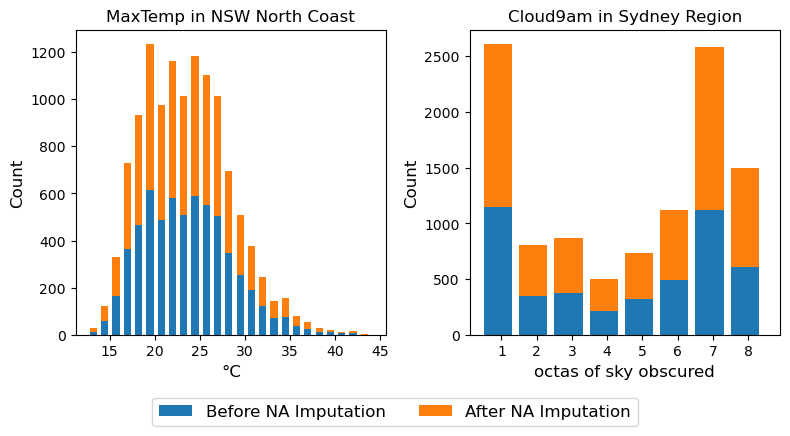

In [39]:
distsid_2=df2[(df2["Location"]=="NSW North Coast")]
distsa_2=df2[(df2["Location"]=="Sydney Region")]


plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.hist(
    [distsid["MaxTemp"], distsid["MaxTemp"]],
    bins=25,
    width=0.8,
    histtype='barstacked',
    label=["Before NA Imputation", "After NA Imputation"]
)


plt.xlabel("°C", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.title("MaxTemp in NSW North Coast",  fontsize=12);


plt.subplot(1,2,2)

plt.hist(
    [distsa["Cloud9am"], distsa_2["Cloud9am"]],
    bins=np.arange(0.5, 9.5, 1),
    width=0.8,
    histtype='barstacked',
    label=["Before NA Imputation", "After NA Imputation"]
)

plt.xlabel("octas of sky obscured", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks([1,2,3,4,5,6,7,8],[1,2,3,4,5,6,7,8])
plt.title("Cloud9am in Sydney Region", fontsize=12)

handles, labels = plt.gca().get_legend_handles_labels()
plt.gcf().legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=2,
    fontsize=12
)

plt.tight_layout(rect=[0, 0.12, 1, 1]);
plt.tight_layout();

**Imputate NAs in TestBase**

In [44]:
test_base = impute_by_location(test_base, "MaxTemp")
test_base = impute_by_location(test_base, "Rainfall")
test_base = impute_by_location(test_base, "WindGustSpeed")
test_base = impute_by_location(test_base, "WindSpeed9am")
test_base = impute_by_location(test_base, "WindSpeed3pm")
test_base = impute_by_location(test_base, "Humidity9am")
test_base = impute_by_location(test_base, "Humidity3pm")
test_base = impute_by_location(test_base, "Pressure3pm")
test_base = impute_by_location(test_base, "Temp9am")
test_base = impute_by_location(test_base, "RainToday")
test_base = impute_by_location(test_base, "Cloud9am")
test_base = impute_by_location(test_base, "WindDir3pm_sin")
test_base = impute_by_location(test_base, "WindDir3pm_cos")

Missing values in 'MaxTemp': 0
Missing values in 'Rainfall': 0
Missing values in 'WindGustSpeed': 0
Missing values in 'WindSpeed9am': 0
Missing values in 'WindSpeed3pm': 0
Missing values in 'Humidity9am': 0
Missing values in 'Humidity3pm': 0
Missing values in 'Pressure3pm': 0
Missing values in 'Temp9am': 0
Missing values in 'RainToday': 0
Missing values in 'Cloud9am': 0
Missing values in 'WindDir3pm_sin': 0
Missing values in 'WindDir3pm_cos': 0


**Target Distribution**

In [45]:
print("train base RainTomorrow: ")
print(train_base["RainTomorrow"].value_counts(normalize=True))
print("\n")
print("test base RainTomorrow: ")
print(test_base["RainTomorrow"].value_counts(normalize=True))

train base RainTomorrow: 
No     0.77621
Yes    0.22379
Name: RainTomorrow, dtype: float64


test base RainTomorrow: 
No     0.775832
Yes    0.224168
Name: RainTomorrow, dtype: float64


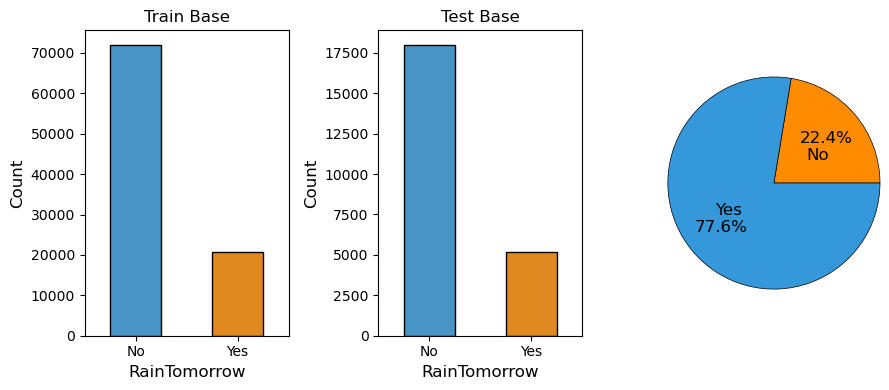

In [46]:
per=[22.4,77.6]

plt.figure(figsize=(9,4))

plt.subplot(1,3,1)

sns.countplot(x="RainTomorrow", data=train_base, hue="RainTomorrow", palette=["#FF8C00", "#3498db"], order=["No", "Yes"], width=0.5, edgecolor="black")
plt.title("Train Base", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xlabel("RainTomorrow", fontsize=12)

plt.subplot(1,3,2)
sns.countplot(x="RainTomorrow", data=test_base, hue="RainTomorrow", palette=["#3498db", "#FF8C00"], order=["No", "Yes"], width=0.5, edgecolor="black")
plt.title("Test Base", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xlabel("RainTomorrow", fontsize=12)

plt.subplot(1,3,3)
plt.pie(per, labels=["No", "Yes"], autopct = lambda x: str(round(x, 2)) + '%', 
        colors=["#FF8C00", "#3498db"], radius=1.3, 
        wedgeprops={"edgecolor": "black", "linewidth": 0.5},
        labeldistance=0.4,
        pctdistance=0.65,
        textprops={"fontsize": 12})

plt.tight_layout();

**Standard Scaler**

In [47]:
from sklearn.preprocessing import StandardScaler

num_cols = train_base.select_dtypes(include=["int","float"])

sc = StandardScaler()
train_base[num_cols.columns] = sc.fit_transform(train_base[num_cols.columns])
test_base[num_cols.columns] = sc.transform(test_base[num_cols.columns])


In [50]:
train_base.to_csv("train_base.csv", index=False)
test_base.to_csv("test_base.csv", index=False)